# 01a — Exploratory Data Analysis (EDA)
**COMP 370 · Project 1: Politician in the Media · Zohran Mamdani**

**Scope:** My collection batch only (`2025-01-01__2025-06-24.csv`). This notebook checks completeness, representation, and article quality **before human annotation**. Flags below are **review suggestions, not automatic exclusions or labels**. The original CSV/JSON will not be changed.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FILENAME = "2025-01-01__2025-06-24.csv"
# Works from the project root or notebooks/, and with files next to this notebook.
candidates = [
    Path.cwd() / "data/raw/csv_data" / FILENAME,
    Path.cwd().parent / "data/raw/csv_data" / FILENAME,
    Path.cwd() / FILENAME,
    Path.cwd().parent / FILENAME,
]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(f"Place {FILENAME} in data/raw/csv_data/, or beside the notebook.")

df = pd.read_csv(csv_path).fillna("")
df["published_at"] = pd.to_datetime(df["published_at"], utc=True, errors="coerce")
print(f"Loaded {len(df)} articles from: {csv_path}")

json_path = csv_path.parent.parent / "json_data" / FILENAME.replace(".csv", ".json")
if not json_path.exists():
    json_path = csv_path.with_suffix(".json")
if json_path.exists():
    with open(json_path, encoding="utf-8") as f:
        raw_json = json.load(f)
    same_ids = {x.get("uuid") for x in raw_json} == set(df["uuid"])
    print(f"CSV ↔ JSON match: {len(raw_json)} JSON records; same UUIDs = {same_ids}")


Loaded 210 articles from: /mnt/data/2025-01-01__2025-06-24.csv
CSV ↔ JSON match: 210 JSON records; same UUIDs = True


## 1 · Dataset overview

In [2]:
title_desc_snippet = df[["title", "description", "snippet"]].agg(" ".join, axis=1)
no_name = ~title_desc_snippet.str.contains(r"\bmamdani\b", case=False, regex=True)
generic_desc = df["description"].str.strip().str.casefold().eq("the nation magazine")
identical_titles = df["title"].duplicated(keep=False)
truncated_snippet = df["snippet"].str.strip().str.endswith(("...", "…"))

summary = pd.DataFrame({
    "Measure": ["Total records", "Unique publishers", "Publication window", "Missing descriptions",
                "Missing keywords (optional)", "Duplicate UUIDs / URLs", "Repeated-title records",
                "Generic descriptions", "Truncated snippets", "No 'Mamdani' in visible text"],
    "Value": [len(df), df["source"].nunique(),
              f"{df['published_at'].min():%Y-%m-%d} to {df['published_at'].max():%Y-%m-%d}",
              df["description"].eq("").sum(), df["keywords"].eq("").sum(),
              f"{df['uuid'].duplicated().sum()} / {df['url'].duplicated().sum()}",
              identical_titles.sum(), generic_desc.sum(), truncated_snippet.sum(), no_name.sum()]
})
display(summary)
print("Note: 'No Mamdani' only means the name is absent from the available text; do NOT delete these records automatically.")


,Measure,Value
0,Total records,210
1,Unique publishers,28
2,Publication window,2025-01-27 to 2025-06-23
3,Missing descriptions,1
4,Missing keywords (optional),83
5,Duplicate UUIDs / URLs,0 / 0
6,Repeated-title records,2
7,Generic descriptions,12
8,Truncated snippets,208
9,No 'Mamdani' in visible text,71


Note: 'No Mamdani' only means the name is absent from the available text; do NOT delete these records automatically.


## 2 · Collection imbalance
Compare publication month and publisher frequencies. These plots describe **this batch**, not the complete North American news landscape.

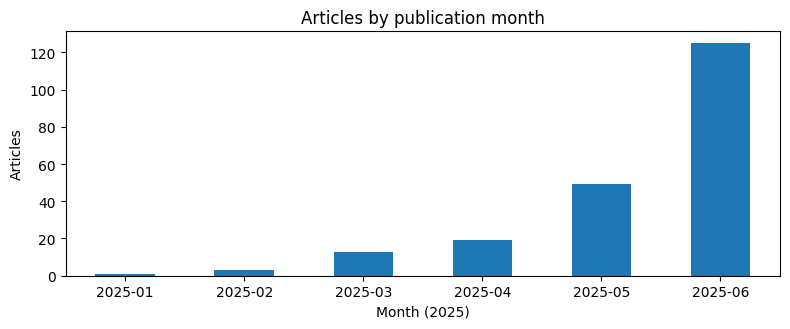

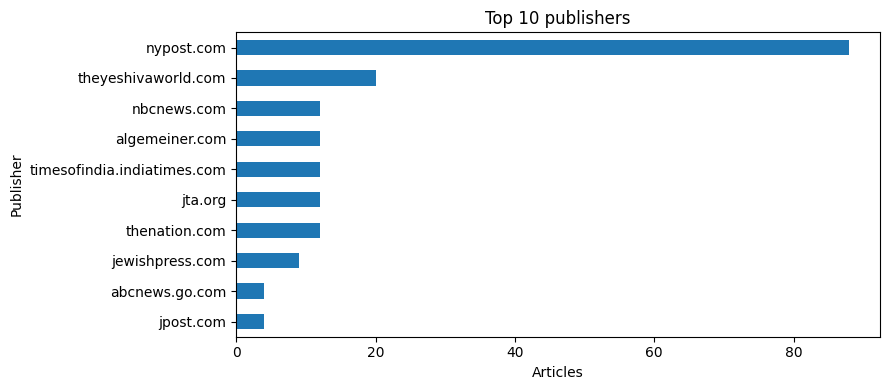

June: 125 / 210 (59.5%)
Top publisher: nypost.com — 88 / 210 (41.9%)
Sorted by API relevance score (descending): True


In [3]:
monthly = df.groupby(df["published_at"].dt.strftime("%Y-%m")).size().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.4))
monthly.plot(kind="bar", ax=ax)
ax.set(title="Articles by publication month", xlabel="Month (2025)", ylabel="Articles")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

sources = df["source"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
sources.head(10).sort_values().plot(kind="barh", ax=ax)
ax.set(title="Top 10 publishers", xlabel="Articles", ylabel="Publisher")
plt.tight_layout()
plt.show()

print(f"June: {monthly.get('2025-06', 0)} / {len(df)} ({monthly.get('2025-06', 0)/len(df):.1%})")
print(f"Top publisher: {sources.index[0]} — {sources.iloc[0]} / {len(df)} ({sources.iloc[0]/len(df):.1%})")
print(f"Sorted by API relevance score (descending): {df['relevance_score'].is_monotonic_decreasing}")


## 3 · Data-quality review flags

- **Publisher geography:** the collection API used `locale=us,ca,mx`, but this batch still contains publishers based outside North America. Domain-based candidates below require verification.
- **Text quality:** generic descriptions, truncated snippets, and reused excerpts can distort topic/sentiment annotation.
- **Relevance:** an article can be about Mamdani without mentioning his name in the retrieved excerpt. **Human review is required.**
- **Article type:** video, sponsored content, and short liveblog entries may not fit a consistent article definition.

In [4]:
# Explicit shortlist of domains to verify; never treat the domain as definitive geographic proof.
possible_non_na = {
    "timesofindia.indiatimes.com", "jpost.com", "israelnationalnews.com",
    "dnaindia.com", "ndtv.com", "defence.pk", "swarajyamag.com",
    "thequint.com", "rediff.com", "dailyexcelsior.com",
}
non_na_review = df["source"].isin(possible_non_na)
non_article_review = df["url"].str.contains(
    r"/video/|/liveblogs/|/sponsored-posts/", regex=True, case=False
)
reused_snippet = df["snippet"].duplicated(keep=False)
newsletter_boilerplate = df["snippet"].str.contains(
    "Welcome to the online version of From the Politics Desk", case=False, regex=False
)

flags = {
    "No name in visible title/description/snippet": no_name,
    "Publisher location needs verification": non_na_review,
    "Generic/missing description": generic_desc | df["description"].eq(""),
    "Repeated headline": identical_titles,
    "Identical snippets across records": reused_snippet,
    "Newsletter boilerplate": newsletter_boilerplate,
    "Potential non-article URL": non_article_review,
}
flag_counts = pd.DataFrame({"Review flag": list(flags), "Records": [int(f.sum()) for f in flags.values()]})
display(flag_counts)

df_review = df[["uuid", "published_at", "source", "title", "description", "snippet", "url"]].copy()
df_review["review_flags"] = [
    "; ".join(label for label, mask in flags.items() if bool(mask.iloc[i]))
    for i in range(len(df))
]
flagged = df_review.loc[df_review["review_flags"].ne("")]
print(f"Unique records flagged for ≥1 check: {len(flagged)} of {len(df)}")
# Examples of different issues, not a complete exclusion list.
sample_indices = []
for label, mask in flags.items():
    candidates = df.index[mask]
    if len(candidates):
        pick = next((idx for idx in candidates if idx not in sample_indices), candidates[0])
        if pick not in sample_indices:
            sample_indices.append(pick)
print("Example records to inspect:")
with pd.option_context("display.max_colwidth", 65):
    display(df_review.loc[sample_indices, ["source", "title", "review_flags"]])


,Review flag,Records
0,No name in visible title/description/snippet,71
1,Publisher location needs verification,27
2,Generic/missing description,13
3,Repeated headline,2
4,Identical snippets across records,5
5,Newsletter boilerplate,3
6,Potential non-article URL,10


Unique records flagged for ≥1 check: 116 of 210
Example records to inspect:


,source,title,review_flags
107,algemeiner.com,NYC Mayor Eric Adams Tells Jewish Leaders One of His Election...,No name in visible title/description/snippet
1,jpost.com,Zohran Mamdani criticized for his antisemitic comments,Publisher location needs verification
0,thenation.com,Can Zohran Mamdani Really Win?,Generic/missing description
197,jta.org,Brad Lander just cursed Andrew Cuomo in Yiddish,No name in visible title/description/snippet; Repeated headline
2,newrepublic.com,Andrew Cuomo Ad Deceptively Edits Photo of Zohran Mamdani,Identical snippets across records
158,nbcnews.com,"In Washington and across the country, lawmakers express safet...",No name in visible title/description/snippet; Identical snipp...
24,nbcnews.com,NYC mayoral candidate Zohran Mamdani responds to accusations ...,Potential non-article URL


## 4 · Before annotation: decisions for the team

1. **Agree on inclusion criteria:** North American publisher (verify), relevant to Mamdani, and a genuine article with usable title + opening. Apply the same criteria to each teammate's batch.
2. **Manually review flags:** do not auto-drop records based on missing name, sentiment, publisher, or title. Check repeated headlines/syndicated copies and mismatched excerpts; keep an exclusion log.
3. **Use consistent annotation text:** prefer a meaningful title + actual opening; document any use of the API's truncated snippet as a substitute. Preserve original fields.
4. **Combine cleaned batches, then deduplicate again** using URLs, headlines and manual checks. Sample 200 articles across the combined dataset for **human open coding**; develop 3–8 topic definitions, then manually annotate topic and positive/neutral/negative framing for the remaining articles.

**Limitation to report:** this collection was paginated in relevance order, and publisher/month counts are imbalanced. Explain how the group manages these sampling limitations rather than claiming a representative census of news coverage.

*No automated topic or sentiment labels are produced by this notebook.*